In [1]:
import os
import numpy as np
import pyvista as pv
import matplotlib as mpl
import matplotlib.pyplot as plt

from wakis import SolverFIT3D
from wakis import GridFIT3D
from wakis import WakeSolver
from wakis import geometry

# os.environ['CUDA_VISIBLE_DEVICES'] = '1'

pv.global_theme.trame.server_proxy_enabled = True
pv.global_theme.trame.server_proxy_prefix = "/proxy/"
pv.global_theme.window_size = [1500, 1200]  # optional

In [2]:
stl_fingers = "notebooks/clara_stl/finger_subdivide1.stl"
# stl_fingers='notebooks/clara_stl/finger_subdiv3.stl'
surf_fingers = pv.read(stl_fingers)
stl_body = "notebooks/clara_stl/012_LHC_WVM_6L2-316l_meters.stl"
surf_body = pv.read(stl_body)
stl_ttube = "notebooks/clara_stl/012_LHC_WVM_6L2-cucamera_meters.stl"
surf_ttube = pv.read(stl_ttube)
stl_spring = "notebooks/clara_stl/012_LHC_WVM_6L2-martensite_meters.stl"
surf_spring = pv.read(stl_spring)
# stl_cucamera_closed='notebooks/clara_stl/VSIMIO_closed_transition_tube_meters.stl'
# surf_cucamera_closed= pv.read(stl_cucamera_closed)

# geometry.measure_stl_slice([stl_body, stl_fingers, stl_spring, stl_ttube])

In [3]:
# ---------- Domain setup ---------
surf = (
    pv.read(stl_body) + pv.read(stl_fingers) + pv.read(stl_spring) + pv.read(stl_ttube)
)
# surf.scale(1e-3, inplace=True)  # scale to meters

xmin, xmax, ymin, ymax, zmin, zmax = surf.bounds
Lx, Ly, Lz = (xmax - xmin), (ymax - ymin), (zmax - zmin)

# Number of mesh cells

Nx = 500
Ny = 500
Nz = 500


# Readjust for PML
dz0 = (zmax - zmin) / Nz
n_pml = 10
zmin -= dz0 * n_pml
zmax += dz0 * n_pml
Nz += 2 * n_pml

stl_solids = {
    "body": stl_body,
    "fingers": stl_fingers,
    "spring": stl_spring,
    "ttube": stl_ttube,
}

stl_materials = {
    "body": "pec",
    "fingers": "pec",
    "spring": "pec",
    "ttube": "pec",
}


# set grid and geometry
grid = GridFIT3D(
    xmin,
    xmax,
    ymin,
    ymax,
    zmin,
    zmax,
    int(Nx),
    int(Ny),
    int(Nz),
    stl_solids=stl_solids,
    stl_materials=stl_materials,
    stl_method="voxelize_rectilinear",  # 'voxelize' or 'cutcell'
    subpixel_smoothing=True,
    # stl_scale=1e-3,
    verbose=2,
)

Generating grid with 130000000 mesh cells...
    * Simulation domain bounds: 
                x:[-0.152, 0.101],
                y:[-0.110, 0.186],
                z:[-0.006, 0.315]
    * Minimum cell sizes: dx=5.060e-04, dy=5.930e-04, dz=6.171e-04
Importing STL solids...
 * Marking cells inside STL solid 'body'...


Converting polydata: 100%|█████████████████████████████████████████[00:11<00:00]
Generating binary mask: 100%|██████████████████████████████████████[00:00<00:00]


    * Applying subpixel smoothing with factor 4...
    * STL solid body: 9644739.980391536 cells marked inside the solid.
 * Marking cells inside STL solid 'fingers'...


Converting polydata: 100%|█████████████████████████████████████████[00:05<00:00]
Generating binary mask: 100%|██████████████████████████████████████[00:00<00:00]


    * Applying subpixel smoothing with factor 4...
    * STL solid fingers: 109665.16240995718 cells marked inside the solid.
 * Marking cells inside STL solid 'spring'...


Converting polydata: 100%|█████████████████████████████████████████[00:00<00:00]
Generating binary mask: 100%|██████████████████████████████████████[00:00<00:00]


    * Applying subpixel smoothing with factor 4...
    * STL solid spring: 11491.067109601747 cells marked inside the solid.
 * Marking cells inside STL solid 'ttube'...


Converting polydata: 100%|█████████████████████████████████████████[00:02<00:00]
Generating binary mask: 100%|██████████████████████████████████████[00:00<00:00]


    * Applying subpixel smoothing with factor 4...
    * STL solid ttube: 3226435.0845158 cells marked inside the solid.
Total grid initialization time: 1080.5681586265564 s


In [5]:
%matplotlib ipympl


spotlight = pv.Light(
    light_type="camera light",  # Keeps the light aligned with your view direction
    positional=True,  # Enables a localized cone of light (spotlight)
    cone_angle=180,  # Sets the sharpness/width of the beam (in degrees)
    exponent=180,  # Focuses the beam intensity towards the center
    color="white",  # Defines the light color
)

# 1. Combine your boolean masks into a single label array
# We initialize with zeros (background)
combined_mask = np.zeros(grid.grid.n_cells)  # use n_points if point data

komponenter = ["body", "fingers", "ttube", "spring"]
for komp in komponenter:
    data = grid.grid[komp]
    maske = data != 0
    combined_mask[maske] = data[maske].astype(float)


# Add it to your grid object
grid.grid["Mask Parts"] = combined_mask
center = grid.grid.center

# 2. Slice it once
grid_slice = grid.grid.slice(normal="x", origin=center)
surf_slice = surf.slice(normal="x", origin=center)
pl = pv.Plotter()

pl.add_mesh(
    grid_slice,
    scalars="Mask Parts",
    cmap="viridis",
    show_edges=True,
    edge_color="black",
    line_width=0.3,
    show_scalar_bar=False,
)
pl.add_mesh(surf_slice, color="red", opacity=0.5, show_edges=True, line_width=5)
pl.view_yz()
pl.camera.up = (0, -1, 0)
pl.enable_3_lights()
pl.enable_anti_aliasing()
pl.show()

Widget(value='<iframe src="/proxy/36161/index.html?ui=P_0x1461677b92e0_1&reconnect=auto" class="pyvista" style…

In [31]:
scalar = "fingers"
stl_surf = stl_fingers

%matplotlib ipympl


cells_inside = grid.grid.threshold(value=0.2, scalars=scalar)


pl = pv.Plotter()
pl.add_mesh(stl_surf, color="white", opacity=0.10, label="STL surface")
pl.add_mesh_clip_plane(
    cells_inside,
    color="yellow",
    show_edges=True,
    label="grid.grid['shell'] cells",
    normal="x",
    widget_color="white",
)
pl.camera_position = "zy"
pl.add_axes()
pl.add_legend()
pl.camera.zoom(1.5)
pl.enable_3_lights()
pl.show()

Widget(value='<iframe src="/proxy/38391/index.html?ui=P_0x154c3e787f50_18&reconnect=auto" class="pyvista" styl…

In [32]:
pv.set_jupyter_backend("trame")

cells_inside = grid.grid.threshold(value=0.1, scalars=scalar)

pl = pv.Plotter()
pl.add_mesh(stl_surf, color="white", opacity=0.10, label="STL surface")
pl.add_mesh_clip_plane(
    cells_inside,
    scalars=scalar,
    cmap="viridis",
    show_edges=True,
    label="grid.grid['shell'] cells",
    normal="x",
    # widget_color='white',
)
pl.camera_position = "zy"
pl.add_axes()
pl.add_legend()
pl.camera.zoom(1.5)
pl.enable_3_lights()
pl.screenshot(f"{results_folder}/mask_{scalar}.png")
pl.show()

Widget(value='<iframe src="/proxy/38391/index.html?ui=P_0x154c3e78af00_19&reconnect=auto" class="pyvista" styl…

In [ ]:
"""for key in stl_solids:
    grid.grid[key] = (grid.grid[key] > 0.1).astype(int)

combined_mask = np.zeros(grid.grid.n_cells)  # eller n_points

komponenter = ["body", "fingers", "ttube", "spring"]
for komp in komponenter:
    data = grid.grid[komp]
    maske = data != 0 
    combined_mask[maske] = data[maske]

grid.grid['bool Mask Parts'] = combined_mask
center = grid.grid.center

grid_slice = grid.grid.slice(normal='x', origin=center) 

pl = pv.Plotter()
pl.add_mesh(
    grid_slice,           
    scalars='bool Mask Parts', 
    cmap='viridis',
    show_edges=True, 
    edge_color="black",
    line_width=0.3,
    show_scalar_bar=False
)
pl.add_mesh(surf_slice, color='red', opacity=0.5, show_edges=True, line_width=5)
pl.view_yz()
pl.camera.up = (0, -1, 0)
pl.enable_3_lights()
pl.enable_anti_aliasing() 
pl.show()
"""

In [33]:
# ------------ Beam source ----------------
# Beam parameters
sigmaz = 50e-3  # [m] -> 2 GHz
q = 1e-9  # [C]
beta = 1.0  # beam beta
xs = 0.0  # x source position [m]
ys = 0.0  # y source position [m]
xt = 0.0  # x test position [m]
yt = 0.0  # y test position [m]
# [DEFAULT] tinj = 8.53*sigmaz/c_light  # injection time offset [s]

# Simualtion
wakelength = 30.0  # [m]
add_space = 70  # no. cells

run_folder = "clara_data/SCS_test_6L2/"
results_folder = run_folder + f"/500gridres_012_results_noContact_70cellsboundary/"
wake = WakeSolver(
    wakelength=wakelength,
    q=q,
    sigmaz=sigmaz,
    beta=beta,
    xsource=xs,
    ysource=ys,
    xtest=xt,
    ytest=yt,
    add_space=add_space,
    results_folder=results_folder,
    Ez_file=results_folder + "Ez.h5",
    verbose=1,
)

Initializing Wakefield parameters...
Total solver initialization time: 0.00030040740966796875 s


In [34]:
# boundary conditions
bc_low = ["pec", "pec", "pml"]
bc_high = ["pec", "pec", "pml"]

solver = SolverFIT3D(
    grid,
    wake,
    cfln=0.6,
    bc_low=bc_low,
    bc_high=bc_high,
    use_stl=True,
    use_gpu=True,
    # use_sibc=True,
    dtype=np.float32,
    bg="vacuum",
    verbose=2,
)

Initializing Electromagnetic solver...
    * Maximum frequency set to fmax=1.9986163866666662 GHz
Assembling operator matrices...
Applying boundary conditions...
Adding material tensors...
    * Max resolved conductivity without SIBC: 618.7565417459501 S/m


/afs/cern.ch/work/c/cwimmelm/Wakis/wakis/solverFIT3D.py:470: RuntimeWarning: invalid value encountered in multiply
  eps_eff = mask * eps + (1.0 - mask) * eps_0


Filling PML sigmas...
    * PML thickness: 10 cells
Calculating maximal stable timestep...
    * Simulation timestep: dt=1.307e-12 s
    * Total simulation time for wakelength=30.0 m: tmax=1.026e-07 s
    * Total number of timesteps for wakelength=30.0 m: Nt=78486
Pre-computing...
Moving to GPU...
Total solver initialization time: 24.10598921775818 s


In [35]:
# %matplotlib inline
%matplotlib ipympl
# solver.ieps.inspect(grid=grid, plane='ZY', dpi=200, figsize=(12,8), backend='pyvista', cmap='Reds_r', background=False)
# solver.ieps.inspect(grid=grid, plane='ZY', dpi=200, figsize=(12,8), backend='pyvista',cmap='Reds_r')
solver.sigma.inspect(
    grid=grid,
    plane="ZY",
    dpi=200,
    figsize=(12, 8),
    backend="pyvista",
    cmap="Reds_r",
    position=0,
)
# solver.ieps.inspect(plane='ZY', dpi=200, figsize=(12,8), cmap='Reds')

Widget(value='<iframe src="/proxy/38391/index.html?ui=P_0x154c344bac60_20&reconnect=auto" class="pyvista" styl…

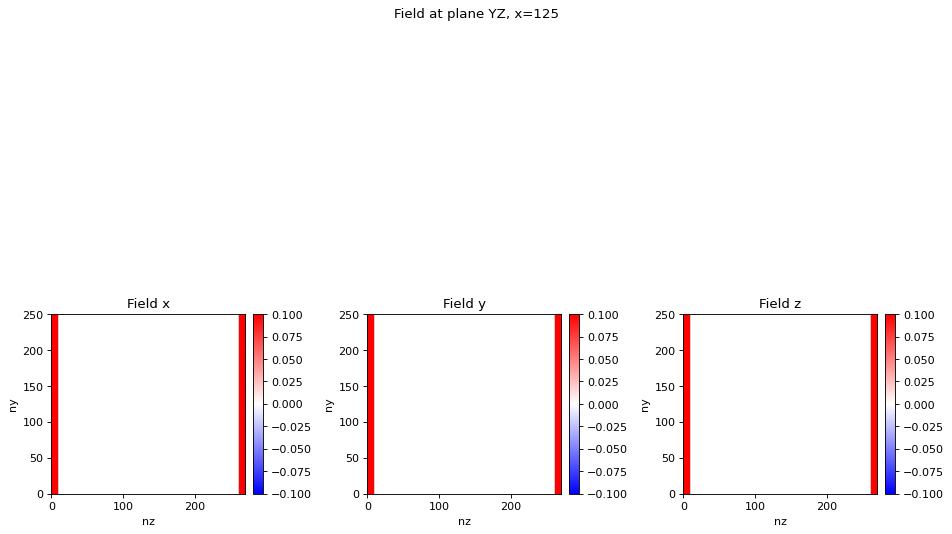

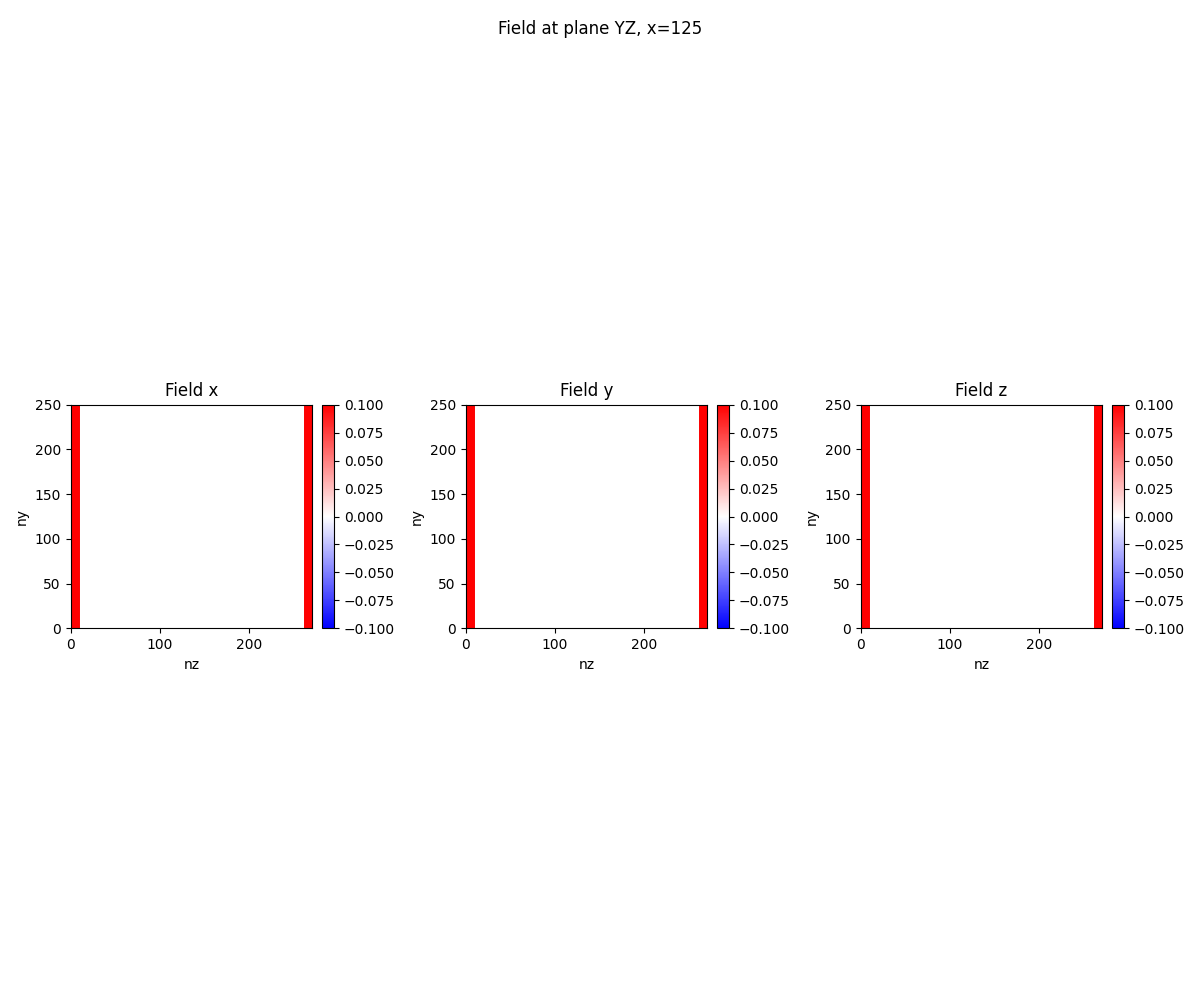

In [36]:
%matplotlib ipympl
import matplotlib.pyplot as plt

# 2. Get the figure handles instead of letting the method try to show it
fig, axs = solver.ieps.inspect(plane="YZ", figsize=[12, 10], x=0.0, handles=True)

# 3. Explicitly display it in the notebook
from IPython.display import display

display(fig)

# 4. If it STILL doesn't show up in the notebook, save it to AFS
fig.savefig(f"{results_folder}/my_ieps_check.png")

plt.show()

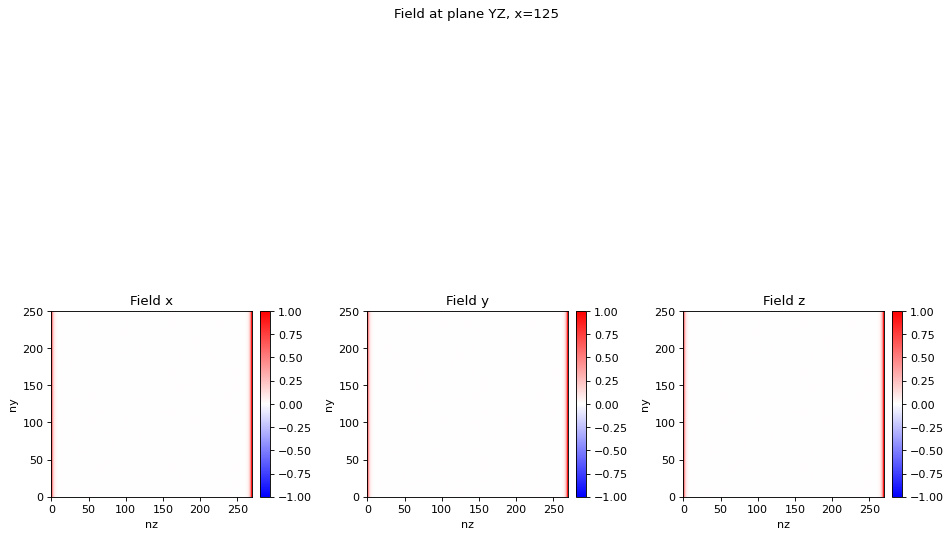

In [37]:
# solver.sigma.inspect

import matplotlib.pyplot as plt

# 2. Get the figure handles instead of letting the method try to show it
fig, axs = solver.sigma.inspect(plane="YZ", figsize=[12, 10], x=0.0, handles=True)

# 3. Explicitly display it in the notebook
from IPython.display import display

display(fig)

# 4. If it STILL doesn't show up in the notebook, save it to AFS
fig.savefig(f"{results_folder}/my_sigma_check.png")

# plt.show()

In [38]:
solver.get_plotting_kwargs("plot2D")
plot_kwargs = {
    "field": "E",
    "component": "Abs",
    "plane": "ZY",
    "pos": 0.5,
    "norm": None,
    "vmin": 0,
    "vmax": 500,
    "figsize": [12, 4],
    "cmap": "plasma",
    "patch_alpha": 0.8,
    "patch_reverse": False,
    "add_patch": ["body", "fingers", "spring", "ttube"],
    "title": results_folder + "animations/" + "Eabs",
    "off_screen": True,
    "interpolation": "spline36",
    "dpi": 200,
    "return_handles": "False",
}

plot_kwargs

{'field': 'E',
 'component': 'Abs',
 'plane': 'ZY',
 'pos': 0.5,
 'norm': None,
 'vmin': 0,
 'vmax': 500,
 'figsize': [12, 4],
 'cmap': 'plasma',
 'patch_alpha': 0.8,
 'patch_reverse': False,
 'add_patch': ['body', 'fingers', 'spring', 'ttube'],
 'title': 'clara_data/SCS_test_6L2//012_results_noContact_70cellsboundary/animations/Eabs',
 'off_screen': True,
 'interpolation': 'spline36',
 'dpi': 200,
 'return_handles': 'False'}

In [39]:
solver.plot2D(
    **plot_kwargs,
)

In [40]:
# Run wakefield time-domain simulation
solver.wakesolve(
    wakelength=wakelength,
    plot=True,
    plot_func=solver.plot2D,
    plot_every=100,
    plot_until=30000,
    **plot_kwargs,
)

Running electromagnetic time-domain simulation...


  9%|███▎                                | 7300/78486 [07:59<1:17:54, 15.23it/s]


ValueError: 

^
ParseException: exception raised in parse action  (at char 0), (line:1, col:1)

In [6]:
pl = solver.E.inspect(
    grid=grid,
    plane="YZ",
    dpi=200,
    figsize=(12, 8),
    backend="pyvista",
    cmap="plasma",
    handles=True,
    off_screen=True,
)
# pl.enable_3_lights()

NameError: name 'solver' is not defined

In [ ]:
import PIL.Image
import glob
import os

# 1. Find all the saved screenshots
# Adjust the pattern if your title was different
image_files = sorted(glob.glob(f"{results_folder}/animations/Eabs_*.png"))

if not image_files:
    print("No images found! Check if plot_every was triggered.")
else:
    # 2. Open images and save as GIF
    images = [PIL.Image.open(f) for f in image_files]

    output_gif = f"{results_folder}/dielectric_barriers.gif"
    images[0].save(
        output_gif,
        save_all=True,
        append_images=images[1:],
        duration=100,  # ms per frame (10 FPS)
        loop=0,
    )
    print(f"GIF saved to {output_gif}")

### Plot results

In [ ]:
import numpy as np
from wakis import WakeSolver
from matplotlib import pyplot as plt

wake = WakeSolver(sigmaz=50e-3)
# results_folder = '012_results_pml/'
results_folder = f"clara_data/SCS_test_6L2/012_results_noContact/"
wake.load_results(results_folder)
# wake.solve(skip_cells=70)

In [ ]:
# %matplotlib ipympl
%matplotlib inline
# ----------- 1d plot results --------------------
# Plot longitudinal wake potential and impedance
from matplotlib import cm
import scienceplots

plt.style.use(["science", "ieee"])


fig1, ax = plt.subplots(1, 2, figsize=[12, 4], dpi=150, layout="constrained")
ax[0].plot(wake.s * 1e3, wake.WP, c="b", lw=2, alpha=0.7, label="Wakis")
ax[0].set_xlabel("s [mm]")
ax[0].set_ylabel("Longitudinal wake potential [V/pC]", color="r")
ax[0].legend()
ax[0].set_xlim(xmax=wake.s[-1] * 1e3)

ax[1].plot(wake.f * 1e-9, np.real(wake.Z), c="b", lw=2, alpha=0.7, label="Re - Wakis")
ax[1].plot(
    wake.f * 1e-9, np.imag(wake.Z), c="b", lw=2, alpha=0.7, ls="--", label="Im - Wakis"
)
ax[1].set_xlabel("f [GHz]")
ax[1].set_ylabel("Longitudinal impedance [Abs][ $ \Omega $ ]", color="b")
ax[1].legend()
# ax[1].set_ylim(ymin=0)

# cstWP = wake.read_txt(f'cst/WP_6L2_closed_ttube_allPEC_NOmeshref_120.txt')
# cstZ = wake.read_txt(f'cst/Z_6L2_closed_ttube_allPEC_NOmeshref_120.txt')
# cstWP = wake.read_txt(f'clara_data/CST/6l2/WP_nmesh10M_wk3e4.txt')
# cstZ = wake.read_txt(f'clara_data/CST/6l2/Z_nmesh10M_wk3e4.txt')
# cstZ_2 = wake.read_txt(f'cst/Z_6L2_allPEC_meshref_35.txt')
# cstZ_3 = wake.read_txt(f'cst/Z_6L2_allPEC_meshref_40.txt')
# cstZ_4 = wake.read_txt(f'cst/Z_6L2_allPEC_meshref_45.txt')
cstZ_4 = wake.read_txt(f"cst/Z_6L2_meshref_50.txt")
cstWP = wake.read_txt(f"cst/WP_6L2_meshref_50.txt")

colors = cm.Reds(np.linspace(0.2, 0.8, 4))

ax[0].plot(cstWP[0], cstWP[1], c="r", lw=1.5, label="CST")
# ax[1].plot(cstZ[0], cstZ[1], c=colors[0], lw=1.5, label="Re - CST - 30M mesh")
"""
ax[1].plot(cstZ_2[0], cstZ_2[1], c=colors[1], lw=1.5, label="Re - CST - 30M mesh")
ax[1].plot(cstZ_3[0], cstZ_3[1], c=colors[2], lw=1.5, label="Re - CST - 40M mesh")
ax[1].plot(cstZ_4[0], cstZ_4[1], c=colors[3], lw=1.5, label="Re - CST - 45M mesh")

#ax[1].plot(cstZ[0], cstZ[2], c="k", ls='--', lw=1.5, label="CST")
ax[1].plot(cstZ_2[0], cstZ_2[2], c=colors[1], lw=1.5, ls='--', label="Im - CST - 30M mesh")
ax[1].plot(cstZ_3[0], cstZ_3[2], c=colors[2], lw=1.5, ls='--', label="Im - CST - 40M mesh")
ax[1].plot(cstZ_4[0], cstZ_4[2], c=colors[3], lw=1.5, ls='--', label="Im - CST - 45M mesh")
"""
ax[1].plot(cstZ[0], cstZ[2], c="k", ls="--", lw=1.5, label="CST")
ax[0].axhline(0, c="grey", ls="--", lw=1)
ax[1].axhline(0, c="grey", ls="--", lw=1)
ax[0].legend()
ax[1].legend()

# fig1.tight_layout()
fig1.savefig(results_folder + "001_longitudinal.png")
plt.show()

# # Plot transverse x wake potential and impedance
# fig2, ax = plt.subplots(1, 2, figsize=[12, 4], dpi=150)
# ax[0].plot(wake.s * 1e2, wake.WPx, c="r", lw=1.5, label="Wakis")
# ax[0].set_xlabel("s [cm]")
# ax[0].set_ylabel("Transverse wake potential X [V/pC]", color="r")
# ax[0].legend()
# ax[0].set_xlim(xmax=wake.s[-1] * 1e2)

# ax[1].plot(wake.f * 1e-9, np.abs(wake.Zx), c="b", lw=1.5, label="Wakis")
# ax[1].set_xlabel("f [GHz]")
# ax[1].set_ylabel("Transverse impedance X [Abs][$\Omega$]", color="b")
# ax[1].legend()

# fig2.tight_layout()
# fig2.savefig(results_folder + "001_transverse_x.png")
# plt.show()

# # Plot transverse y wake potential and impedance
# fig3, ax = plt.subplots(1, 2, figsize=[12, 4], dpi=150)
# ax[0].plot(wake.s * 1e2, wake.WPy, c="r", lw=1.5, label="Wakis")
# ax[0].set_xlabel("s [cm]")
# ax[0].set_ylabel("Transverse wake potential Y [V/pC]", color="r")
# ax[0].legend()
# ax[0].set_xlim(xmax=wakelength * 1e2)

# ax[1].plot(wake.f * 1e-9, np.abs(wake.Zy), c="b", lw=1.5, label="Wakis")
# ax[1].set_xlabel("f [GHz]")
# ax[1].set_ylabel("Transverse impedance Y [Abs][$\Omega$]", color="b")
# ax[1].legend()

# fig3.tight_layout()
# fig3.savefig(results_folder + "001_transverse_y.png")
# plt.show()

In [ ]:
!convert -loop 0 -delay 10 012_results_pml/Ez_*.png 012_results_pml/Ez.gif

In [ ]:
# %matplotlib ipympl
%matplotlib inline

import numpy as np
from wakis import WakeSolver
import matplotlib.pyplot as plt
import matplotlib.cm as cm

# ----------- Compare multiple result folders --------------------
# Define folders and labels to compare
folders_to_compare = [
    ("012_results_noContact_67M/", "noContact 67M"),
    ("012_results_noContact_28M/", "noContact 28M"),
    ("012_results_noContact_17M/", "noContact 17M"),
    # ('012_results_allContact_28M/', 'allContact 28M'),
]

# Optional CST reference files (set to None to skip)
cst_WP_file = "cst/WP_nmesh10M_wk3e4.txt"
cst_Z_file = "cst/Z_6L2_allPEC_meshref_45.txt"  #'cst/Z_nmesh10M_wk3e4.txt'

skip_cells = 70  # cells to skip at boundaries when solving

# ---------------------------------------------------------------
colors = cm.rainbow(np.linspace(0.1, 0.9, len(folders_to_compare)))

fig, ax = plt.subplots(1, 2, figsize=[14, 5], dpi=150)

for (folder, label), color in zip(folders_to_compare, colors):
    try:
        w = WakeSolver(sigmaz=50e-3)
        w.load_results(folder)
        w.solve(skip_cells=skip_cells)
        ax[0].plot(w.s * 1e3, w.WP, lw=2, alpha=0.7, color=color, label=label)
        ax[1].plot(
            w.f * 1e-9,
            np.real(w.Z),
            lw=2,
            color=color,
            alpha=0.7,
            label=f"Re – {label}",
        )
        # ax[1].plot(w.f * 1e-9, np.imag(w.Z), lw=2, color=color, alpha=0.7,  ls='--', label=f'Im – {label}')
    except Exception as e:
        print(f"[SKIP] {folder}: {e}")

# CST reference
if cst_WP_file and cst_Z_file:
    _w = WakeSolver(sigmaz=50e-3)
    try:
        cstWP = _w.read_txt(cst_WP_file)
        cstZ = _w.read_txt(cst_Z_file)
        ax[0].plot(cstWP[0], cstWP[1], c="k", lw=1.5, label="CST")
        ax[1].plot(cstZ[0], cstZ[1], c="k", lw=1.5, label="Re – CST")
        # ax[1].plot(cstZ[0],  cstZ[2],  c='k', lw=1.5, ls='--', label='Im – CST')
    except Exception as e:
        print(f"[SKIP] CST files: {e}")

ax[0].set_xlabel("s [mm]")
ax[0].set_ylabel("Longitudinal wake potential [V/pC]")
ax[0].legend(fontsize=8)

ax[1].set_xlabel("f [GHz]")
ax[1].set_ylabel("Longitudinal impedance [$\\Omega$]")
ax[1].legend(fontsize=8)

fig.tight_layout()
fig.savefig("012_comparison_skip70.png", dpi=150)
plt.show()

In [ ]:
plt.close("all")